# Ownership and board control

## What OneCredit uses this for

The control page of a OneCredit report says who can decide for the company the customer is about to trust.

- A disclosed holder of 25% can block a special resolution. A holder of 50% carries the ordinary vote. Those two cuts are the control tests on the top-10 file.
- The holder-type stakes say whether control sits with a corporation, with the individual-investor bucket, or with institutions.
- The board check is the listing test of one-third independent directors, counted only where every seat has a designation.
- The interlock count says how widely the same published director name sits across issuers. It is a name match, so two people who share a name are one key.

A listed credit file treats control as a number, not a narrative. Three extracts carry it:

- `data/top_10_investors.csv` — named holders and stakes. The largest stake is the control test: 25% can block a special resolution, 50% carries ordinary control.
- `data/ownership_type.csv` — the same register rolled into holder types (corporation, individual bucket, mutual fund, and the other institutional labels).
- `data/directors_executives.csv` and `data/individual_shareholder.csv` — board seats, and substantial individual holders.

The top-10 Herfindahl is the sum of squared disclosed fractions. Holders outside the top 10 are not on the file, so this HHI is the concentration of the disclosed book, not of every share in issue. The largest disclosed stake does not have that gap: a 50% holder appears in the top 10.

Director names in the interlock table are the names published on the Bursa extract. The count is a name match after stripping titles, so two different people who share a name are one key, and one person who files under two spellings is two keys.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "credit_stats.py").exists():
    NOTEBOOK_DIR = Path.cwd() / "notebooks" / "credit_desk"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from credit_stats import (
    DATA_DIR,
    FIGURE_DIR,
    FINANCIAL_SECTOR_NAME,
    INSTITUTIONAL_INVESTOR_TYPES,
    LISTED_AMOUNT_UNIT,
    SSM_AMOUNT_UNIT,
    build_listed_panel,
    clean_state_name,
    age_in_years,
    cramers_v,
    distribution_row,
    epsilon_squared,
    herfindahl_from_positive_amounts,
    latest_rows,
    load_listed_statements,
    ownership_fraction,
    parse_ssm_financials,
    parse_ssm_profiles,
    peer_percentile,
    share_with_interval,
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


In [2]:
top_10 = pd.read_csv(DATA_DIR / "top_10_investors.csv", low_memory=False)
ownership_type = pd.read_csv(DATA_DIR / "ownership_type.csv", low_memory=False)
individual_holders = pd.read_csv(DATA_DIR / "individual_shareholder.csv", low_memory=False)
directors = pd.read_csv(DATA_DIR / "directors_executives.csv", low_memory=False)
profile = pd.read_csv(
    DATA_DIR / "company_profile.csv",
    usecols=["registration_number", "company_name_bursa", "sector"],
    low_memory=False,
)

for frame in (top_10, ownership_type, individual_holders, directors, profile):
    frame["registration_number"] = frame["registration_number"].astype(str).str.strip()

top_10["stake"] = top_10["ownership_"].map(ownership_fraction)
ownership_type["stake"] = ownership_type["ownership_"].map(ownership_fraction)
individual_holders["stake"] = individual_holders["ownership_"].map(ownership_fraction)

# A stake outside [0, 1] is a parse or a source glitch, not a holding.
top_10 = top_10.loc[top_10["stake"].between(0, 1)]
ownership_type = ownership_type.loc[ownership_type["stake"].between(0, 1)]
individual_holders = individual_holders.loc[individual_holders["stake"].between(0, 1)]
print(f"Issuers on the top-10 file: {top_10['registration_number'].nunique():,}")
print(f"Issuers on the ownership-type file: {ownership_type['registration_number'].nunique():,}")


Issuers on the top-10 file: 991
Issuers on the ownership-type file: 991


In [3]:
control_rows = []
for registration_number, holder_frame in top_10.groupby("registration_number"):
    stakes = holder_frame["stake"].tolist()
    largest_stake = max(stakes) if stakes else float("nan")
    disclosed_hhi = float(sum(stake * stake for stake in stakes))
    largest_row = holder_frame.loc[holder_frame["stake"].idxmax()]
    control_rows.append(
        {
            "registration_number": registration_number,
            "holder_count": len(stakes),
            "disclosed_stake_sum": float(sum(stakes)),
            "disclosed_top10_hhi": disclosed_hhi,
            "largest_disclosed_stake": largest_stake,
            "largest_holder_name": largest_row["investor_name"],
            "blocking_stake_25": largest_stake >= 0.25,
            "majority_stake_50": largest_stake >= 0.50,
        }
    )
control = pd.DataFrame(control_rows).merge(profile, on="registration_number", how="left")

blocking = share_with_interval(control["blocking_stake_25"])
majority = share_with_interval(control["majority_stake_50"])
print(
    f"Median disclosed top-10 HHI {control['disclosed_top10_hhi'].median():.3f}. "
    f"Median largest stake {control['largest_disclosed_stake'].median():.1%}."
)
print(
    f"Largest holder ≥ 25%: {blocking['share']:.1%} "
    f"(Wilson {blocking['wilson_low']:.1%}–{blocking['wilson_high']:.1%}, n = {blocking['trials']})."
)
print(
    f"Largest holder ≥ 50%: {majority['share']:.1%} "
    f"(Wilson {majority['wilson_low']:.1%}–{majority['wilson_high']:.1%})."
)
distribution_frame = pd.DataFrame(
    [
        distribution_row(control["disclosed_top10_hhi"], "disclosed_top10_hhi"),
        distribution_row(control["largest_disclosed_stake"], "largest_disclosed_stake"),
        distribution_row(control["disclosed_stake_sum"], "disclosed_stake_sum"),
    ]
)
distribution_frame


Median disclosed top-10 HHI 0.133. Median largest stake 30.3%.
Largest holder ≥ 25%: 62.1% (Wilson 59.0%–65.0%, n = 991).
Largest holder ≥ 50%: 23.5% (Wilson 21.0%–26.3%).


,ratio,n,median,mean,p25,p75,iqr,skew,excess_kurtosis,mad_outlier_share
0,disclosed_top10_hhi,991,0.1328,0.1754,0.0671,0.2591,0.1920,1.1545,1.3075,0.0111
1,largest_disclosed_stake,991,0.3029,0.3402,0.1992,0.4890,0.2898,0.4870,-0.6607,0.0000
2,disclosed_stake_sum,991,0.6833,0.6562,0.5391,0.7813,0.2422,-0.2933,0.8858,0.0050


In [4]:
type_rows = []
for registration_number, type_frame in ownership_type.groupby("registration_number"):
    institutional_stake = float(
        type_frame.loc[
            type_frame["investor_name"].isin(INSTITUTIONAL_INVESTOR_TYPES), "stake"
        ].sum()
    )
    individual_bucket = float(
        type_frame.loc[type_frame["investor_name"].eq("Individual Investor"), "stake"].sum()
    )
    corporation_stake = float(
        type_frame.loc[type_frame["investor_name"].isin(["Corporation", "Holding Company"]), "stake"].sum()
    )
    type_rows.append(
        {
            "registration_number": registration_number,
            "institutional_stake": institutional_stake,
            "individual_bucket_stake": individual_bucket,
            "corporation_stake": corporation_stake,
        }
    )
holder_types = pd.DataFrame(type_rows)
print(
    "Median stake by holder type (a type row is already an aggregate on the source file):"
)
print(f"  Institutional labels combined: {holder_types['institutional_stake'].median():.1%}")
print(f"  Individual Investor bucket: {holder_types['individual_bucket_stake'].median():.1%}")
print(f"  Corporation + holding company: {holder_types['corporation_stake'].median():.1%}")

insider_sum = individual_holders.groupby("registration_number")["stake"].sum()
insider_max = individual_holders.groupby("registration_number")["stake"].max()
print(
    f"Substantial individual holders: median of the largest named individual "
    f"{insider_max.median():.1%} across {insider_max.shape[0]:,} issuers. "
    f"Median sum of named individual stakes {insider_sum.median():.1%}."
)
holder_types.describe().T[["count", "50%", "mean"]]


Median stake by holder type (a type row is already an aggregate on the source file):
  Institutional labels combined: 1.2%
  Individual Investor bucket: 22.5%
  Corporation + holding company: 32.1%
Substantial individual holders: median of the largest named individual 6.2% across 946 issuers. Median sum of named individual stakes 19.3%.


,count,50%,mean
institutional_stake,991.0000,0.0123,0.0815
individual_bucket_stake,991.0000,0.2246,0.2883
corporation_stake,991.0000,0.3211,0.3213


In [5]:
designation = directors["designation"].fillna("").str.lower()
is_secretary = designation.str.contains("secretary")
is_director_seat = (~is_secretary) & (
    directors["role"].isin(["Director", "Both"])
    | designation.str.contains("director")
    | designation.str.contains("chairman")
)
directors = directors.loc[is_director_seat].copy()
seat_designation = designation.loc[directors.index]
# "Non-Independent" contains the substring "independent", so the
# independence flag has to reject that token explicitly.
directors["is_independent"] = seat_designation.str.contains("independent") & ~seat_designation.str.contains(
    "non-independent"
) & ~seat_designation.str.contains("non independent")
directors["designation_known"] = seat_designation.str.strip().ne("")

def normalise_person_name(raw_name: str) -> str:
    """Upper-case the Bursa name and drop titles so 'Mr. A. B.' matches 'A. B.'."""
    text = " ".join(str(raw_name).upper().replace(".", " ").split())
    titles = {
        "MR", "MRS", "MS", "MDM", "DR", "DATO", "DATUK", "DATO'", "DATUK'",
        "TAN SRI", "PUAN SRI", "TUN", "TOH PUAN", "ENCIK", "CIK", "IR", "PROF",
    }
    # Two-word titles first, then single tokens.
    for title in ("TAN SRI", "PUAN SRI", "TOH PUAN"):
        if text.startswith(title + " "):
            text = text[len(title) + 1 :]
    tokens = [token for token in text.split() if token not in titles]
    return " ".join(tokens)

directors["person_key"] = directors["name"].map(normalise_person_name)
directors = directors.loc[directors["person_key"].str.len() > 0]
directors = directors.drop_duplicates(["registration_number", "person_key"])

board = directors.groupby("registration_number").agg(
    board_size=("person_key", "nunique"),
    independent_seats=("is_independent", "sum"),
    seats_with_designation=("designation_known", "sum"),
)
board["independent_fraction"] = board["independent_seats"] / board["board_size"]
# The one-third test is only fair when every retained seat had a designation.
# A blank designation would otherwise be counted as non-independent.
board["designation_complete"] = board["seats_with_designation"].eq(board["board_size"])
classified = board.loc[board["designation_complete"] & board["board_size"].ge(2)]
below_one_third = share_with_interval(classified["independent_fraction"].lt(1 / 3))

seat_counts = directors.groupby("person_key")["registration_number"].nunique()
multi_board = share_with_interval(seat_counts.ge(2))
three_boards = share_with_interval(seat_counts.ge(3))

print(f"Issuers with at least one director seat: {len(board):,}")
print(f"Median board size: {board['board_size'].median():.0f}")
print(
    f"Boards with a designation on every seat: {len(classified):,} of {len(board):,}. "
    f"Among those, independent fraction below one third: {below_one_third['share']:.1%} "
    f"(Wilson {below_one_third['wilson_low']:.1%}–{below_one_third['wilson_high']:.1%})."
)
print(
    f"Person keys on two or more boards: {multi_board['share']:.1%} of {multi_board['trials']:,}. "
    f"On three or more: {three_boards['share']:.1%}."
)

interlock_table = (
    seat_counts.loc[seat_counts.ge(4)]
    .sort_values(ascending=False)
    .head(15)
    .rename("board_count")
    .reset_index()
)
interlock_table


Issuers with at least one director seat: 971
Median board size: 7
Boards with a designation on every seat: 971 of 971. Among those, independent fraction below one third: 15.6% (Wilson 13.4%–18.0%).
Person keys on two or more boards: 13.6% of 5,824. On three or more: 3.3%.


,person_key,board_count
0,ZAHA RINA BINTI ZAHARI,5
1,TEE KEIN ONG,5
2,KIEN YOON KOO,5
3,MIN ON LEE,5
4,MOHAMAD FUZI BIN HARUN,5
5,JEE MIN LIEW,5
6,HAW CHOON CHIAU,5
7,SIK EEK TAN,5
8,HOON HONG CHUAH,5
9,WEY SENG LEOW,5


In [6]:
majority_holders = (
    control.loc[control["majority_stake_50"]]
    .sort_values("largest_disclosed_stake", ascending=False)
    [
        [
            "company_name_bursa",
            "sector",
            "largest_holder_name",
            "largest_disclosed_stake",
            "disclosed_top10_hhi",
        ]
    ]
    .head(15)
)
print(f"Issuers whose largest disclosed holder is at least half the shares: {int(control['majority_stake_50'].sum())}")
majority_holders


Issuers whose largest disclosed holder is at least half the shares: 233


,company_name_bursa,sector,largest_holder_name,largest_disclosed_stake,disclosed_top10_hhi
857,BV LAND HOLDINGS BERHAD,Others,Goh (Kang Beng),0.9501,0.9027
821,BABA ECO GROUP BERHAD,Consumer Cyclicals,Leong (Jyh Wen),0.8197,0.6721
965,99 SPEED MART RETAIL HOLDINGS BERHAD,Consumer Non-Cyclicals,Lee (Thiam Wah),0.7968,0.6388
292,APOLLO FOOD HOLDINGS BERHAD,Consumer Non-Cyclicals,Scoop Capital Sdn Bhd,0.7479,0.5631
247,LOTTE CHEMICAL TITAN HOLDING BERHAD,Basic Materials,Lotte Chemical Corp,0.7472,0.5590
258,DKSH HOLDINGS (MALAYSIA) BERHAD,Industrials,DKSH Resources (Malaysia) Sdn Bhd,0.7431,0.5536
561,MYCRON STEEL BERHAD,Basic Materials,Melewar Industrial Group Bhd,0.7413,0.5512
912,SYNERGY HOUSE BERHAD,Consumer Cyclicals,Synergy House Furniture Holdings Sdn Bhd.,0.7400,0.5513
565,ABM FUJIYA BERHAD,Consumer Cyclicals,Kayatas Sdn. Bhd.,0.7398,0.5499
91,MENTIGA CORPORATION BERHAD,Consumer Non-Cyclicals,Amanah Saham Pahang Berhad,0.7391,0.5493


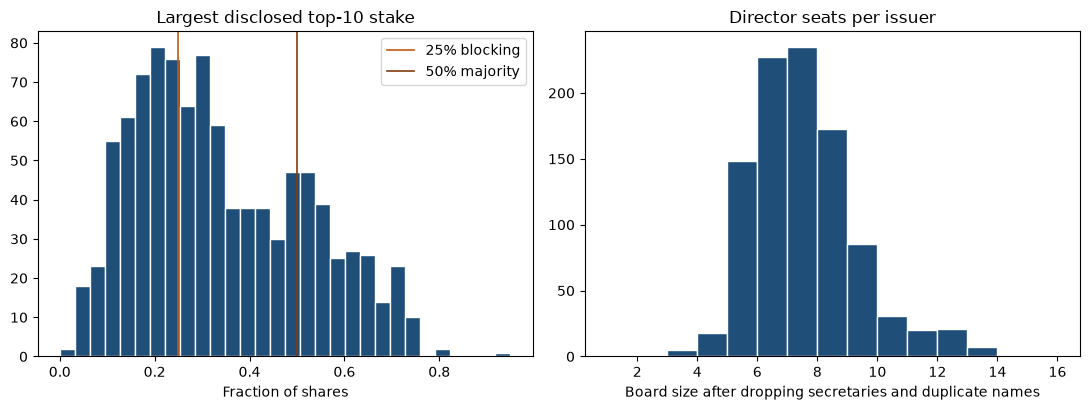

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(control["largest_disclosed_stake"], bins=30, color="#1f4e79", edgecolor="white")
axes[0].axvline(0.25, color="#c45911", linewidth=1.2, label="25% blocking")
axes[0].axvline(0.50, color="#833c0c", linewidth=1.2, label="50% majority")
axes[0].set_title("Largest disclosed top-10 stake")
axes[0].set_xlabel("Fraction of shares")
axes[0].legend()

axes[1].hist(board["board_size"], bins=range(1, int(board["board_size"].max()) + 2), color="#1f4e79", edgecolor="white")
axes[1].set_title("Director seats per issuer")
axes[1].set_xlabel("Board size after dropping secretaries and duplicate names")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "03_ownership_and_board_control.png", dpi=140)
plt.show()
